# Real data: lineage-traced single cells

This tutorial runs TwINFER on single-cell RNA-seq data with clone labels from a lineage-tracing experiment (a barcode, CellTag, LARRY, FateMap, ...). Cells that share a label descend from the same labelled cell and form a **clone**. Unlike the simulated twins of the [simulation tutorials](inference_simulation_one_time_point.ipynb), real clones have one to many cells, and many labelled cells are singletons; `infer_with_twinfer` handles this directly.

The steps are the same for any dataset:

1. load the expression matrix and the clone label of every cell;
2. choose the cells of one sample / time point and the genes;
3. normalise (if the matrix holds raw counts) and build the input table: one row per cell, `clone_id`, one column per gene;
4. score the gene pairs: three z-scores, Benjamini-Hochberg correction, inference scenario;
5. rank the pairs and draw the network.

Several choices **depend on the dataset**: which columns hold the clone label and the sample, whether the matrix holds raw counts, which cells and genes to use. Each of them is marked **Depends on the dataset**, followed by what we do for LARRY, the example below.

**Example data.** The repository ships one dataset, used here: mouse haematopoietic progenitors barcoded with LARRY and sequenced 2, 4 and 6 days later (Weinreb et al., *Science* 2020), `real_data/LSK_d2_d4_d6.h5ad` (238 MB, stored with Git LFS: run `git lfs pull` after cloning if the file is only a small text pointer).

## 1. Setup and data

Results are written to `tutorial_output/real_data_lineage_tracing/`, next to this notebook; change `output_dir` to save them elsewhere. `infer_with_twinfer(..., save_to=path)` saves its result table (`.csv`, `.csv.gz`, `.tsv` or `.parquet`) and writes the settings of the call next to it (`<name>_settings.json`); `save_result(table, path)` saves any other table the same way.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse

from twinfer.inference.covariance_decomposition_z_scores import INFERENCE_SCENARIOS, infer_with_twinfer, save_result
from twinfer.inference.ranked_edges import ranked_edge_lists
from twinfer.plotting.network_plots import network_from_scenarios, plot_grn
from twinfer.utils.paths import get_repo_root

warnings.filterwarnings("ignore", message="Observation names are not unique")   # repeated 10x barcodes, see below
output_dir = Path("tutorial_output") / "real_data_lineage_tracing"   # where the results are saved
adata = ad.read_h5ad(get_repo_root() / "real_data" / "LSK_d2_d4_d6.h5ad")
adata

AnnData object with n_obs × n_vars = 72946 × 25289
    obs: 'Library', 'Time point', 'Starting population', 'Cell type annotation', 'Well', 'SPRING-x', 'SPRING-y', 'clone_id', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

**Depends on the dataset.** Any AnnData object (or a cells × genes matrix with a table of cell annotations) works. The settings below name the column of `adata.obs` with the clone label, the value that marks cells without a clone, the column with the sample / time point, and whether `X` holds raw counts or normalised values.

**For LARRY:** the clone label is `clone_id`, cells without a detected barcode have `clone_id = -1`, the samples are the days in `Time point` (2, 4, 6), and `X` is already normalised by the authors (each cell scaled to the same total, then log1p), so it is used as it is.

In [2]:
# ============ depends on the dataset (values for LARRY) ============
clone_column = "clone_id"          # clone label of each cell
unlabelled = -1                    # value of cells without a clone label (None if every cell has one)
sample_column = "Time point"       # sample / time point; each is scored separately
x_is_raw_counts = False            # True: X holds raw counts (normalised below); False: X is already normalised
# =================================================================

Check what `X` holds before setting `x_is_raw_counts`: raw counts are whole numbers. **For LARRY** the values are not whole numbers and are at most about 6 (log scale): already normalised.

In [3]:
sample = adata.X[:1000]
sample = sample.toarray() if scipy.sparse.issparse(sample) else np.asarray(sample)
print("whole numbers only:", bool(np.allclose(sample, np.round(sample))), "| largest value:", float(sample.max()))

whole numbers only: False | largest value: 6.358935832977295


## 2. Clones per sample

Clones with two or more cells give the twin terms (`z_rho_s`, `z_rho_Delta`), from all their within-clone cell pairs, each clone with weight 1. Singletons contribute only to the expression correlation (`z_rho`). The more clones with two or more cells, the more power.

In [4]:
obs = adata.obs
labelled = (obs[clone_column] != unlabelled) if unlabelled is not None else pd.Series(True, index=obs.index)
rows = []
for value, group in obs[labelled].groupby(sample_column, observed=True):
    sizes = group[clone_column].value_counts()
    rows.append({sample_column: value, "cells with a clone": len(group), "clones": len(sizes),
                 "clones with >= 2 cells": int((sizes >= 2).sum()), "singletons": int((sizes == 1).sum()),
                 "largest clone": int(sizes.max())})
clones_per_sample = pd.DataFrame(rows).set_index(sample_column)
clones_per_sample

,cells with a clone,clones,clones with >= 2 cells,singletons,largest clone
Time point,,,,,
2.0,2809,1625,863,762,6
4.0,6121,2497,1674,823,12
6.0,15978,2630,2150,480,50


## 3. Build the input table

`input_table` selects the labelled cells of one sample and the genes, normalises raw counts as log1p of counts per 10,000 (with each cell's total over **all** genes, before the genes are selected), and keeps the genes detected (count > 0) in at least 5 % of the cells: with almost only zeros, a rank correlation carries little information. Cells are selected by position, so repeated cell names (common when 10x barcodes recur across libraries) do not matter.

In [5]:
def input_table(adata, sample, genes, min_detection=0.05):
    # one row per labelled cell of `sample`: clone_id + normalised expression of the detected genes
    keep = (adata.obs[sample_column] == sample).to_numpy() & labelled.to_numpy()
    sub = adata[keep]
    X = sub.X.tocsr() if scipy.sparse.issparse(sub.X) else np.asarray(sub.X)
    columns = [sub.var_names.get_loc(g) for g in genes]
    values = X[:, columns]
    values = values.toarray() if scipy.sparse.issparse(values) else np.asarray(values, dtype=float)
    if x_is_raw_counts:
        totals = np.asarray(X.sum(axis=1)).ravel()                      # library size over all genes
        values = np.log1p(values / totals[:, None] * 1e4)
    detected = (values > 0).mean(axis=0) >= min_detection
    table = pd.DataFrame(values[:, detected], columns=np.array(genes)[detected])
    table.insert(0, "clone_id", sub.obs[clone_column].to_numpy())
    return table


def sample_folder(value):
    # results of one sample are saved in output_dir/<sample column>_<value>/
    return output_dir / f"{sample_column.replace(' ', '_')}_{value:g}"

**Depends on the dataset.** Choose the sample and the genes: a panel of regulators and markers, the highly variable genes, or transcription factors and their candidate targets (for example from ChIP-seq). The 5 % detection floor can also be changed (`min_detection`).

**For LARRY:** day 2 (the earliest sample, closest to sister cells) and a panel of haematopoietic regulators and lineage markers.

In [6]:
# ============ depends on the dataset (values for LARRY) ============
panel = ["Gata1", "Gata2", "Gfi1", "Gfi1b", "Fli1", "Spi1", "Tal1", "Cebpa", "Cebpb", "Jun", "Egr1", "Zfpm1", "Irf8",
         "Runx1", "Myb", "Meis1", "Hlf", "Ikzf1", "Lmo2", "Erg", "Hoxa9", "Mycn", "Myc",                 # regulators
         "Mpo", "Elane", "Prtn3", "Ctsg", "Pf4", "Itga2b", "Csf1r"]                                       # lineage markers
sample = 2                                                                                               # day 2
# =================================================================
panel = [g for g in panel if g in adata.var_names]
cells = input_table(adata, sample, panel)
genes = list(cells.columns[1:])
print(f"{len(cells)} cells, {cells['clone_id'].nunique()} clones, {len(genes)} of {len(panel)} genes detected in >= 5 % of cells")
cells.head()

2809 cells, 1625 clones, 24 of 30 genes detected in >= 5 % of cells


,clone_id,Gata2,Gfi1,Fli1,Spi1,Tal1,Cebpa,Cebpb,Jun,Irf8,...,Erg,Hoxa9,Mycn,Myc,Mpo,Elane,Prtn3,Ctsg,Pf4,Itga2b
0,4187,0.0,0.000000,0.0,0.0,0.0,0.0,1.642228,0.0,0.0,...,0.000000,0.0,0.0,1.642228,0.0,0.000000,0.000000,0.000000,0.0,1.642228
1,94,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,2.246341
2,4544,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
3,1898,0.0,2.707117,0.0,0.0,0.0,0.0,2.078567,0.0,0.0,...,0.000000,0.0,0.0,2.707117,0.0,3.090088,2.707117,3.090088,0.0,0.000000
4,3410,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,1.246371,0.0,0.0,0.000000,0.0,0.000000,0.000000,1.246371,0.0,0.000000


## 4. Score all gene pairs

The table has no `replicate` column, so `infer_with_twinfer` uses the **clones** scenario. Because many pairs are tested at once, `z_rho` is corrected with Benjamini-Hochberg over all pairs (`q_rho`) and `z_rho_Delta` over the pairs whose `z_rho` is significant (`q_rho_Delta`); `z_rho_s` uses its threshold (|z| > 2.326).

In [7]:
result = infer_with_twinfer(cells, genes, save_to=sample_folder(sample) / "z_scores.csv")
print(f"{len(result)} gene pairs; {result['N_clones'].iloc[0]} clones, {result['N_twin_clones'].iloc[0]} with two or more cells")
result[["gene_x", "gene_y", "rho", "z_rho", "q_rho", "z_rho_s", "z_rho_Delta", "q_rho_Delta", "inference_scenario"]].head()

276 gene pairs; 1625 clones, 863 with two or more cells


,gene_x,gene_y,rho,z_rho,q_rho,z_rho_s,z_rho_Delta,q_rho_Delta,inference_scenario
0,Gata2,Gfi1,0.011423,0.539363,0.678082,-0.681899,0.867574,NaN,1
1,Gata2,Fli1,-0.015918,-0.763646,0.566090,-1.078637,1.276906,NaN,1
2,Gata2,Spi1,-0.033936,-1.623535,0.184841,1.727760,1.095024,NaN,1
3,Gata2,Tal1,0.104230,4.996335,0.000004,2.757473,1.405288,0.283165,4
4,Gata2,Cebpa,0.072052,3.428510,0.002428,2.087036,1.268682,0.345185,2


For a large gene set, score only regulator × target pairs, e.g. transcription factors against all genes: `infer_with_twinfer(cells, genes, regulators=tfs, targets=genes)`. The computation runs in blocks (`chunk_x`, `chunk_y`), so tens of thousands of pairs are fine.

### Inference scenarios

In [8]:
counts = result["inference_scenario"].value_counts().sort_index()
pd.DataFrame({"scenario": [INFERENCE_SCENARIOS[s] for s in counts.index], "pairs": counts.values}, index=counts.index)

,scenario,pairs
inference_scenario,,
1,nothing,168
2,regulation,41
3,regulation + heterogeneity,24
4,heterogeneity,43


### Ranked lists

`ranked_edge_lists` ranks the pairs with a significant `z_rho` by |`z_rho_s`| (a shared cell state) and by |`z_rho_Delta`| (regulation inside each cell):

In [9]:
lists = ranked_edge_lists(result, top=10)
lists["z_rho_Delta"]

,rank,gene_x,gene_y,z_rho_Delta,z_rho,q_rho,q_rho_Delta,inference_scenario
0,1,Elane,Ctsg,8.270429,25.412237,5.098043e-140,1.441564e-14,3
1,2,Mpo,Elane,6.751891,24.422095,1.374940e-129,7.880233e-10,3
2,3,Mpo,Ctsg,6.408174,22.409854,2.902336e-109,5.301830e-09,3
3,4,Elane,Prtn3,5.322118,21.640292,5.176820e-102,2.769282e-06,3
4,5,Gfi1,Elane,4.364231,13.307095,8.300058e-39,2.449008e-04,3
5,6,Gfi1,Ctsg,4.350131,11.898127,3.340511e-31,2.449008e-04,3
6,7,Mpo,Prtn3,4.202826,20.341204,2.555278e-90,4.067029e-04,3
7,8,Prtn3,Ctsg,4.164198,20.752383,6.439765e-94,4.218054e-04,3
8,9,Gata2,Itga2b,3.879494,10.542819,1.261102e-24,1.227423e-03,3
9,10,Gfi1,Prtn3,3.859433,12.463690,4.063785e-34,1.227423e-03,3


In [10]:
lists["z_rho_s"]

,rank,gene_x,gene_y,z_rho_s,z_rho,q_rho,q_rho_Delta,inference_scenario
0,1,Elane,Ctsg,15.136480,25.412237,5.098043e-140,1.441564e-14,3
1,2,Mpo,Elane,15.078656,24.422095,1.374940e-129,7.880233e-10,3
2,3,Mpo,Ctsg,14.284206,22.409854,2.902336e-109,5.301830e-09,3
3,4,Elane,Prtn3,13.679352,21.640292,5.176820e-102,2.769282e-06,3
4,5,Prtn3,Ctsg,13.655893,20.752383,6.439765e-94,4.218054e-04,3
5,6,Mpo,Prtn3,13.232682,20.341204,2.555278e-90,4.067029e-04,3
6,7,Gfi1,Mpo,8.931300,12.407419,7.305067e-34,1.257669e-02,3
7,8,Gfi1,Elane,8.731557,13.307095,8.300058e-39,2.449008e-04,3
8,9,Cebpa,Ctsg,8.385949,11.727627,2.308397e-30,1.694779e-02,3
9,10,Gfi1,Prtn3,8.030337,12.463690,4.063785e-34,1.227423e-03,3


**For LARRY**, both lists are led by the neutrophil-granule genes *Mpo*, *Elane*, *Prtn3* and *Ctsg*: they score high on `z_rho_s` (cells of a clone share a granulocytic state) and also on `z_rho_Delta` (within a clone, the cell with more of one has more of the other).

## 5. Network of a group of genes

`network_from_scenarios` turns the result into a network: scenarios 2 and 3 solid, scenario 4 (shared state only) dashed. With one time point there is no direction, so the edges have no arrowheads; colour = `z_rho`. Which genes to draw **depends on the dataset**; **for LARRY** we draw a group of myeloid regulators and the neutrophil-granule genes.

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


,source,target,weight,inference_scenario,line_style,directed
25,Elane,Ctsg,8.270429,3,solid,False
21,Mpo,Elane,6.751891,3,solid,False
23,Mpo,Ctsg,6.408174,3,solid,False
24,Elane,Prtn3,5.322118,3,solid,False
5,Gfi1,Elane,4.364231,3,solid,False
7,Gfi1,Ctsg,4.350131,3,solid,False
22,Mpo,Prtn3,4.202826,3,solid,False
26,Prtn3,Ctsg,4.164198,3,solid,False
6,Gfi1,Prtn3,3.859433,3,solid,False
3,Gfi1,Cebpa,3.581591,3,solid,False


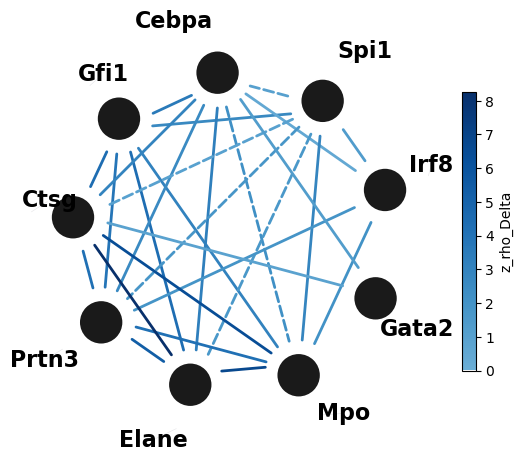

In [11]:
# ============ depends on the dataset (values for LARRY) ============
group = ["Gfi1", "Cebpa", "Spi1", "Irf8", "Gata2", "Mpo", "Elane", "Prtn3", "Ctsg"]
# =================================================================
group = [g for g in group if g in genes]
in_group = result[result["gene_x"].isin(group) & result["gene_y"].isin(group)]
plot_kwargs, edges = network_from_scenarios(in_group, genes=group, weight="z_rho_Delta")   # edge colour = z_rho_Delta
fig, ax = plt.subplots(figsize=(6, 6))
plot_grn(**plot_kwargs, ax=ax, figsize=(8, 8), colorbar_label="z_rho_Delta")
edges.sort_values("weight", key=abs, ascending=False).head(10)

## 6. Several samples

Each sample / time point is scored on its own. Comparing them shows how the balance between regulation and shared states changes, here from day 2 to day 6:

In [12]:
summary, sample_results = [], {}
for value in sorted(obs[sample_column].unique()):
    sample_cells = input_table(adata, value, panel)
    sample_result = infer_with_twinfer(sample_cells, list(sample_cells.columns[1:]),
                                       save_to=sample_folder(value) / "z_scores.csv")
    sample_results[value] = sample_result
    fractions = sample_result["inference_scenario"].value_counts(normalize=True)
    summary.append({sample_column: value, "clones with >= 2 cells": int(sample_result["N_twin_clones"].iloc[0]), "pairs": len(sample_result),
                    **{f"{s} {INFERENCE_SCENARIOS[s]}": round(fractions.get(s, 0.0), 3) for s in (1, 2, 3, 4)}})
summary = pd.DataFrame(summary).set_index(sample_column)
summary

,clones with >= 2 cells,pairs,1 nothing,2 regulation,3 regulation + heterogeneity,4 heterogeneity
Time point,,,,,,
2.0,863,276,0.609,0.149,0.087,0.156
4.0,1674,300,0.307,0.207,0.137,0.350
6.0,2150,276,0.130,0.127,0.395,0.348


**For LARRY**, from day 2 to day 6 fewer pairs stay in scenario 1 (day 6 also has more than twice as many clones with two or more cells), and a larger fraction of the pairs is shared within clones (scenarios 3 and 4), as expected when clones commit to a fate.

## 7. Save the results

Each sample gets its own folder, `<sample column>_<value>/` (here `Time_point_2/`, `Time_point_4/`, `Time_point_6/`), with its scores and their settings (already written by `save_to` in sections 4 and 6), the complete ranked lists by `z_rho_s` and by `z_rho_Delta` (not only the top 10) and the number of pairs per inference scenario. The network of section 5 is saved with the sample it was drawn for. The tables that compare the samples (clones per sample, scenarios per sample) are saved in the main folder.

In [13]:
save_result(clones_per_sample.reset_index(), output_dir / "clones_per_sample.csv")
save_result(summary.reset_index(), output_dir / "scenarios_per_sample.csv")
for value, sample_result in sample_results.items():
    folder = sample_folder(value)
    for score, ranked in ranked_edge_lists(sample_result).items():
        save_result(ranked, folder / f"ranked_by_{score}.csv")
    counts = sample_result["inference_scenario"].value_counts().sort_index()
    save_result(pd.DataFrame({"inference_scenario": counts.index, "scenario": [INFERENCE_SCENARIOS[s] for s in counts.index],
                              "pairs": counts.values}), folder / "scenario_counts.csv")
save_result(edges, sample_folder(sample) / "network_edges.csv")
fig.savefig(sample_folder(sample) / "network.pdf", bbox_inches="tight")
sorted(str(p.relative_to(output_dir)) for p in output_dir.rglob("*") if p.is_file())

['Time_point_2/network.pdf',
 'Time_point_2/network_edges.csv',
 'Time_point_2/ranked_by_z_rho_Delta.csv',
 'Time_point_2/ranked_by_z_rho_s.csv',
 'Time_point_2/scenario_counts.csv',
 'Time_point_2/z_scores.csv',
 'Time_point_2/z_scores_settings.json',
 'Time_point_4/ranked_by_z_rho_Delta.csv',
 'Time_point_4/ranked_by_z_rho_s.csv',
 'Time_point_4/scenario_counts.csv',
 'Time_point_4/z_scores.csv',
 'Time_point_4/z_scores_settings.json',
 'Time_point_6/ranked_by_z_rho_Delta.csv',
 'Time_point_6/ranked_by_z_rho_s.csv',
 'Time_point_6/scenario_counts.csv',
 'Time_point_6/z_scores.csv',
 'Time_point_6/z_scores_settings.json',
 'clones_per_sample.csv',
 'scenarios_per_sample.csv']

## Notes

* **Raw 10x output.** To build an AnnData-like input from 10x matrices and a barcode / clone table, see [`convert_10x_to_twinfer_input.ipynb`](convert_10x_to_twinfer_input.ipynb).
* **Normalisation.** Always pass normalised values; the statistics are rank-based, but ranks of raw counts still depend on each cell's sequencing depth.
* **One time point at a time.** The cross-time direction of the [two-time-point tutorial](inference_simulation_two_time_points.ipynb) needs sisters measured at two times and is not implemented for clone tables.